# 04 · 物理仿真与多模态数据

执行模块三生成的场景、任务和机器人轨迹，在物理与视觉随机化条件下同步记录多模态观测、动作、状态和接触数据，并按真实任务结果归档成功与失败样本。


In [1]:
import json
import uuid

import numpy as np
from examples._display import setup_notebook, show_animation, show_metrics, show_pipeline

PROJECT_ROOT, OUTPUT_DIR = setup_notebook("simulation_and_data_generation")

from physrealx import ArtifactRef, MethodCapability, PhysRealX, RunSpec, VersionedRef

px = PhysRealX.open(PROJECT_ROOT / ".physrealx")
run_key = uuid.uuid4().hex[:12]
physics_backend = "mujoco"  # 可切换为 "isaac_sim"（本机 Isaac Sim 4.5）


Python,3.11.15
解释器,/home/yxp/miniconda3/envs/PhysReal-X/bin/python


## 1. 可执行任务

读取模块三发布的场景、任务、任务实例和已验收轨迹，并核对资源身份。


In [2]:
upstream = json.loads(
    (PROJECT_ROOT / "examples/scene_and_task_generation/output/results.json").read_text()
)
scene_ref = VersionedRef.model_validate(upstream["libraries"]["scenes"][-1])
task_ref = VersionedRef.model_validate(upstream["libraries"]["tasks"][-1])
task_instance_ref = ArtifactRef.model_validate(upstream["task_instance"])
trajectory_ref = ArtifactRef.model_validate(upstream["libraries"]["trajectories"][-1])
task_instance = json.loads(px.artifacts.get_bytes(task_instance_ref))
trajectory = json.loads(px.artifacts.get_bytes(trajectory_ref))
scene = px.scenes.get(scene_ref)
original_task = px.tasks.get(task_ref)
if task_instance["task"] != task_ref.model_dump(mode="json"):
    raise RuntimeError("任务实例与任务资源不一致。")
if trajectory["task"] != task_ref.model_dump(mode="json"):
    raise RuntimeError("轨迹与任务资源不一致。")
show_pipeline(
    {
        "模块三输入": "场景 · 任务 · Panda 轨迹",
        "物理执行": f"{physics_backend} 批量回放",
        "同步采样": "视觉 · 状态 · 接触",
        "质量校核": "成功/失败与数据契约",
        "数据输出": "训练数据集 · 同步动画",
    }
)

## 2. 同步传感与随机化

相机围绕任务目标布置；质量、阻尼、摩擦、初态、光照、颜色、视角和遮挡按 Episode 种子独立采样。


In [3]:
from physrealx.integrations.sensors import CameraSpec

subject = next(entity for entity in scene.entities if entity.name == original_task.subject_entity)
target = np.asarray(subject.pose.translation_m) + np.asarray([0.0, 0.0, 0.12])
camera_specs = {
    name: CameraSpec.look_at(
        target + np.asarray(offset),
        target,
        width=160,
        height=120,
        max_depth_m=5.0,
        event_threshold=0.2,
    )
    for name, offset in {"front": [0.70, -0.72, 0.48], "side": [0.72, 0.48, 0.38]}.items()
}
task = px.tasks.with_sensors(
    original_task,
    scene_ref,
    camera_specs,
    resource_id=f"partnet.laptop.multimodal.{run_key}",
    frequency_hz=20,
)
task_ref = px.tasks.register(task)
backend_config = dict(task_instance["backend_config"])
backend_config.update(
    cameras={name: spec.model_dump(mode="json") for name, spec in camera_specs.items()},
    randomization={
        "mass_scale": [0.95, 1.05],
        "damping_scale": [0.9, 1.1],
        "friction_scale": [0.9, 1.1],
        "initial_position_jitter": 0.002,
        "color_jitter": 0.12,
        "light_jitter": 0.15,
        "camera_position_jitter_m": 0.01,
        "occlusion_probability": 0.2,
        "occlusion_fraction": [0.05, 0.12],
    },
)
backend = px.methods.bind(MethodCapability.SIMULATION_RUN, physics_backend, config=backend_config)
show_metrics(
    {
        "同步信号": len(task.observations),
        "相机": len(camera_specs),
        "动作维度": task.action.signal.shape[0],
    }
)

同步信号,27
相机,2
动作维度,7


## 3. 批量物理执行

专家批次回放模块三轨迹；失败批次保持机器人初态。两类运行共享相同场景、传感器和数据结构。


In [4]:
expert_spec = RunSpec(
    run_id=str(uuid.uuid4()),
    scene=scene_ref,
    task=task_ref,
    backend=backend,
    policy=px.methods.bind(
        MethodCapability.POLICY_INFERENCE,
        "joint_sequence",
        config={"commands": trajectory["commands"]},
    ),
    episode_count=2,
    stop_on_success=False,
    base_seed=20260,
    dataset_id=f"partnet.laptop.expert.{run_key}",
    dataset_version="1.0.0",
    record_signals=tuple(signal.name for signal in task.observations),
    tags=("expert_demonstration", "domain_randomized"),
)
expert_run = px.runs.submit(expert_spec)
expert_result = px.runs.wait(expert_run)
expert_dataset = px.datasets.get(expert_result.dataset)
expert_episodes = px.runs.episodes(expert_run)
if not any(episode.success for episode in expert_episodes):
    raise RuntimeError("专家轨迹未产生成功样本。")

failure_spec = expert_spec.model_copy(
    update={
        "run_id": str(uuid.uuid4()),
        "dataset_id": f"partnet.laptop.failure.{run_key}",
        "base_seed": 30260,
        "policy": px.methods.bind(
            MethodCapability.POLICY_INFERENCE,
            "joint_target",
            config={"target": task_instance["backend_config"]["initial_positions"]},
        ),
        "tags": ("no_motion_failure", "domain_randomized"),
    }
)
failure_run = px.runs.submit(failure_spec)
failure_result = px.runs.wait(failure_run)
failure_dataset = px.datasets.get(failure_result.dataset)
failed_episodes = px.runs.episodes(failure_run)
if any(episode.success for episode in failed_episodes):
    raise RuntimeError("无动作策略意外完成了任务。")
show_metrics(
    {
        "成功样本": sum(episode.success for episode in expert_episodes),
        "失败样本": sum(not episode.success for episode in expert_episodes + failed_episodes),
        "每条轨迹帧数": len(expert_episodes[0].steps),
    }
)

成功样本,2
失败样本,2
每条轨迹帧数,201


## 4. 校核、可视化与导出

校核数组、时间戳、单位和标签；统一 Blender PBR 场景同步展示物理执行、front RGB-D、实例/Link Mask、XYZRGB 点云与状态曲线。


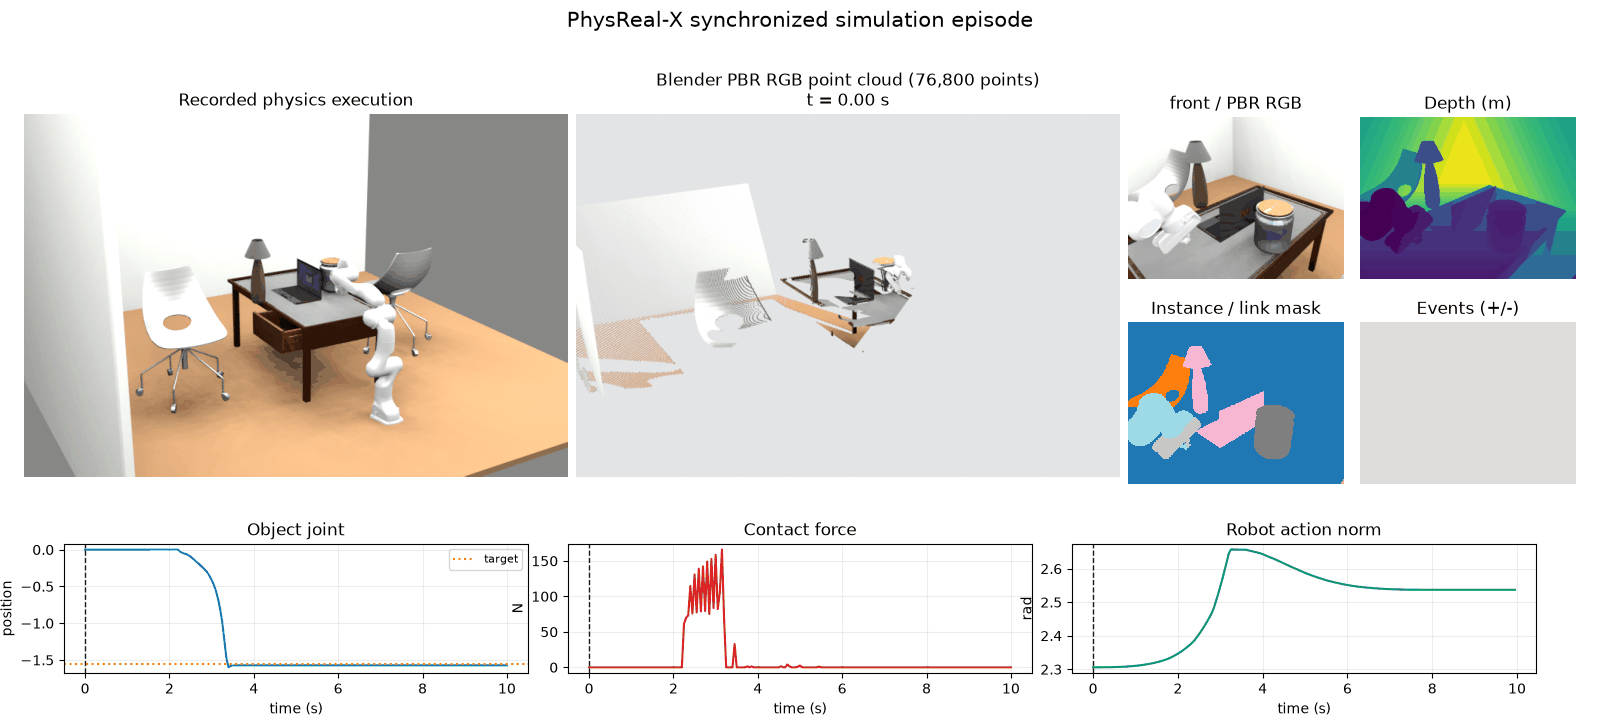

数据集,2
总样本,4
同步数组,12864
质量状态,PASSED


结果索引: /mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/examples/simulation_and_data_generation/output/results.json


In [5]:
from physrealx.integrations.datasets import EpisodeCollection, validate_dataset

expert_quality = validate_dataset(px.artifacts, expert_dataset)
failure_quality = validate_dataset(px.artifacts, failure_dataset)
collection = px.artifacts.put_json(
    EpisodeCollection(datasets=(expert_result.dataset, failure_result.dataset))
)
dataset_operation = px.datasets.ingest(
    collection,
    method="episode_dataset",
    config={"resource_id": f"partnet.laptop.simulation.{run_key}", "version": "1.0.0"},
)
quality_report = dataset_operation.output("quality_report")
preview = px.datasets.preview_episode(
    expert_result.dataset,
    episode_index=next(index for index, episode in enumerate(expert_episodes) if episode.success),
    camera="front",
    frames=12,
    fps=6,
    sensor_source="recorded" if physics_backend == "isaac_sim" else "blender",
)
show_animation(px.artifacts.get_bytes(preview))
show_metrics(
    {
        "数据集": 2,
        "总样本": len(expert_episodes) + len(failed_episodes),
        "同步数组": expert_quality["checked_arrays"] + failure_quality["checked_arrays"],
        "质量状态": json.loads(px.artifacts.get_bytes(quality_report))["status"],
    }
)
px.artifacts.export(
    OUTPUT_DIR,
    {
        "source": {
            "scene": scene_ref.model_dump(mode="json"),
            "task": task_instance["task"],
            "task_instance": task_instance_ref.model_dump(mode="json"),
            "trajectory": trajectory_ref.model_dump(mode="json"),
        },
        "sensor_task": task_ref.model_dump(mode="json"),
        "expert_dataset": expert_result.dataset.model_dump(mode="json"),
        "failure_dataset": failure_result.dataset.model_dump(mode="json"),
        "episode_collection": collection.model_dump(mode="json"),
        "simulation_dataset": dataset_operation.output("dataset").model_dump(mode="json"),
        "quality_report": quality_report.model_dump(mode="json"),
        "evaluation_run": expert_spec.model_dump(mode="json"),
        "preview": preview.model_dump(mode="json"),
        "summary": {
            "successful": sum(episode.success for episode in expert_episodes),
            "failed": sum(not episode.success for episode in expert_episodes + failed_episodes),
            "modalities": ["rgb", "depth", "mask", "events", "pointcloud", "pose"],
        },
    },
    files={"simulation-preview.gif": preview},
)
print("结果索引:", OUTPUT_DIR / "results.json")